# Show raw data — look at the 4 datasets before Phase 2
Exploratory only: we load the raw files into **pandas**, look at shape / columns / types, run quick format tests and draw a few plots.
Nothing is cleaned or written to disk (that is Phase 2). Prerequisite: `01_download_data.ipynb` has passed.

In [2]:
import sys, json
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "sources.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from threatgraph import config
pd.set_option("display.max_columns", 30, "display.max_colwidth", 60, "display.width", 200)
RAW = config.RAW_DIR
report = json.loads(config.REPORT_PATH.read_text())
assert report["all_passed"], "Phase 1 gate not passed: run 01_download_data.ipynb first"
print("Phase 1 gate: passed on", report["generated_at_utc"])

Phase 1 gate: passed on 2026-10-13T13:44:45Z


## 1 · KEV — one row per exploited CVE (flat JSON → DataFrame)

In [4]:
kev_doc = json.loads((RAW/"kev"/"known_exploited_vulnerabilities.json").read_text())
kev = pd.DataFrame(kev_doc["vulnerabilities"])
kev["dateAdded"] = pd.to_datetime(kev["dateAdded"]); kev["dueDate"] = pd.to_datetime(kev["dueDate"])
print(kev.shape); display(kev.head(300)); display(kev.dtypes.to_frame("dtype").T)
# format tests
assert kev.shape == (1391, 11) and kev.cveID.is_unique
assert kev.cveID.str.match(r"^CVE-\d{4}-\d{4,}$").all()
assert set(kev.knownRansomwareCampaignUse) == {"Known", "Unknown"}
assert kev.cwes.map(type).eq(list).all()
print("KEV format OK | null cells:", int(kev.isna().sum().sum()))

(1391, 11)


,cveID,vendorProject,product,vulnerabilityName,dateAdded,shortDescription,requiredAction,dueDate,knownRansomwareCampaignUse,notes,cwes
0,CVE-2023-2533,PaperCut,NG/MF,PaperCut NG/MF Cross-Site Request Forgery (CSRF) Vulnera...,2025-07-28,PaperCut NG/MF contains a cross-site request forgery (CS...,"Apply mitigations per vendor instructions, follow applic...",2025-08-18,Unknown,https://www.papercut.com/kb/Main/SecurityBulletinJune202...,[CWE-352]
1,CVE-2025-20337,Cisco,Identity Services Engine,Cisco Identity Services Engine Injection Vulnerability,2025-07-28,Cisco Identity Services Engine contains an injection vul...,"Apply mitigations per vendor instructions, follow applic...",2025-08-18,Unknown,https://sec.cloudapps.cisco.com/security/center/content/...,[CWE-74]
2,CVE-2025-20281,Cisco,Identity Services Engine,Cisco Identity Services Engine Injection Vulnerability,2025-07-28,Cisco Identity Services Engine contains an injection vul...,"Apply mitigations per vendor instructions, follow applic...",2025-08-18,Unknown,https://sec.cloudapps.cisco.com/security/center/content/...,[CWE-74]
3,CVE-2025-2775,SysAid,SysAid On-Prem,SysAid On-Prem Improper Restriction of XML External Enti...,2025-07-22,SysAid On-Prem contains an improper restriction of XML e...,"Apply mitigations per vendor instructions, follow applic...",2025-08-12,Unknown,https://documentation.sysaid.com/docs/24-40-60 ; https:/...,[CWE-611]
4,CVE-2025-2776,SysAid,SysAid On-Prem,SysAid On-Prem Improper Restriction of XML External Enti...,2025-07-22,SysAid On-Prem contains an improper restriction of XML e...,"Apply mitigations per vendor instructions, follow applic...",2025-08-12,Unknown,https://documentation.sysaid.com/docs/24-40-60 ; https:/...,[CWE-611]
...,...,...,...,...,...,...,...,...,...,...,...
295,CVE-2024-3272,D-Link,Multiple NAS Devices,D-Link Multiple NAS Devices Use of Hard-Coded Credential...,2024-04-11,"D-Link DNS-320L, DNS-325, DNS-327L, and DNS-340L contain...",This vulnerability affects legacy D-Link products. All a...,2024-05-02,Unknown,https://supportannouncement.us.dlink.com/security/public...,[CWE-798]
296,CVE-2024-29748,Android,Pixel,Android Pixel Privilege Escalation Vulnerability,2024-04-04,Android Pixel contains a privilege escalation vulnerabil...,Apply mitigations per vendor instructions or discontinue...,2024-04-25,Unknown,https://source.android.com/docs/security/bulletin/pixel/...,[CWE-280]
297,CVE-2024-29745,Android,Pixel,Android Pixel Information Disclosure Vulnerability,2024-04-04,Android Pixel contains an information disclosure vulnera...,Apply mitigations per vendor instructions or discontinue...,2024-04-25,Unknown,https://source.android.com/docs/security/bulletin/pixel/...,[CWE-908]
298,CVE-2023-24955,Microsoft,SharePoint Server,Microsoft SharePoint Server Code Injection Vulnerability,2024-03-26,Microsoft SharePoint Server contains a code injection vu...,Apply mitigations per vendor instructions or discontinue...,2024-04-16,Known,https://msrc.microsoft.com/update-guide/vulnerability/CV...,[CWE-94]


,cveID,vendorProject,product,vulnerabilityName,dateAdded,shortDescription,requiredAction,dueDate,knownRansomwareCampaignUse,notes,cwes
dtype,str,str,str,str,datetime64[us],str,str,datetime64[us],str,str,object


KEV format OK | null cells: 0


## 2 · PKEV — expert mapping CVE → ATT&CK technique (one row per pair)

In [6]:
pk_doc = json.loads(next((RAW/"pkev").glob("kev-*.json")).read_text())
pkev = pd.DataFrame(pk_doc["mapping_objects"])
print(pkev.shape, "| metadata:", {k: pk_doc["metadata"][k] for k in ("attack_version","mapping_framework_version","creation_date","last_update")})
display(pkev.drop(columns=["references"]).head(300))
assert pkev.shape[0] == 1183 and pkev.capability_id.nunique() == 419 and pkev.attack_object_id.nunique() == 155
assert pkev.mapping_type.isin(["exploitation_technique","primary_impact","secondary_impact"]).all()
assert not pkev.duplicated(["capability_id","attack_object_id","mapping_type"]).any(), "duplicate mapping rows"
print("PKEV format OK | missing 'comments':", int(pkev.comments.isna().sum()))

(1183, 10) | metadata: {'attack_version': '16.1', 'mapping_framework_version': '07/28/2025', 'creation_date': '07/28/2025', 'last_update': '08/28/2025'}


,capability_id,capability_description,mapping_type,attack_object_id,attack_object_name,capability_group,comments,status,mapping_framework_version
0,CVE-2024-34102,Adobe Commerce and Magento Open Source Improper Restrict...,exploitation_technique,T1190,Exploit Public-Facing Application,xxe,This vulnerability is exploited by sending a crafted XML...,complete,7/28/2025
1,CVE-2024-34102,Adobe Commerce and Magento Open Source Improper Restrict...,primary_impact,T1059,Command and Scripting Interpreter,xxe,This vulnerability is exploited by sending a crafted XML...,complete,7/28/2025
2,CVE-2024-34102,Adobe Commerce and Magento Open Source Improper Restrict...,secondary_impact,T1005,Data from Local System,xxe,This vulnerability is exploited by sending a crafted XML...,complete,7/28/2025
3,CVE-2019-13608,Citrix StoreFront Server XML External Entity (XXE) Proce...,secondary_impact,T1078,Valid Accounts,xxe,CVE-2019-13608 is a an XML External Entity (XXE) process...,complete,7/28/2025
4,CVE-2019-13608,Citrix StoreFront Server XML External Entity (XXE) Proce...,primary_impact,T1059,Command and Scripting Interpreter,xxe,CVE-2019-13608 is a an XML External Entity (XXE) process...,complete,7/28/2025
...,...,...,...,...,...,...,...,...,...
295,CVE-2023-48365,Qlik Sense HTTP Tunneling Vulnerability,primary_impact,T1059,Command and Scripting Interpreter,other,This vulnerability stems from improper HTTP header valid...,complete,7/28/2025
296,CVE-2022-23748,Dante Discovery Process Control Vulnerability,exploitation_technique,T1203,Exploitation for Client Execution,other,An attacker with local access can exploit a DLL sideload...,complete,7/28/2025
297,CVE-2022-23748,Dante Discovery Process Control Vulnerability,exploitation_technique,T1059,Command and Scripting Interpreter,other,An attacker with local access can exploit a DLL sideload...,complete,7/28/2025
298,CVE-2025-48928,TeleMessage TM SGNL Exposure of Core Dump File to an Una...,exploitation_technique,T1212,Exploitation for Credential Access,other,TeleMessage TM SNGL utilizes a JavaServer Pages framewor...,complete,7/28/2025


PKEV format OK | missing 'comments': 5


## 3 · ATT&CK — STIX 2.1 bundle (objects of many types) → techniques and tactics

In [9]:
at_doc = json.loads(next((RAW/"attack").glob("enterprise-attack-*.json")).read_text())
objs = at_doc["objects"]
types = pd.Series([o["type"] for o in objs]).value_counts()
def ext_id(o): return next((r["external_id"] for r in o.get("external_references", []) if r["source_name"] == "mitre-attack"), None)
tech = pd.DataFrame([{"technique_id": ext_id(o), "name": o["name"], "is_sub": "." in (ext_id(o) or ""),
                      "tactics": [k["phase_name"] for k in o.get("kill_chain_phases", [])],
                      "revoked": o.get("revoked", False), "deprecated": o.get("x_mitre_deprecated", False)}
                     for o in objs if o["type"] == "attack-pattern"])
tactics = pd.DataFrame([{"shortname": o["x_mitre_shortname"], "name": o["name"], "id": ext_id(o)} for o in objs if o["type"] == "x-mitre-tactic"])
print(len(objs), "objects |", len(tech), "techniques |", len(tactics), "tactics"); display(tech.head(14)); display(tactics.head(14))
assert len(objs) == 22905 and len(tech) == 799 and len(tactics) == 14 and tech.technique_id.is_unique
assert tech.technique_id.str.match(r"^T\d{4}(\.\d{3})?$").all()
print("ATT&CK format OK | active:", int((~tech.revoked & ~tech.deprecated).sum()), "revoked:", int(tech.revoked.sum()), "deprecated:", int(tech.deprecated.sum()))

22905 objects | 799 techniques | 14 tactics


,technique_id,name,is_sub,tactics,revoked,deprecated
0,T1055.011,Extra Window Memory Injection,True,"[defense-evasion, privilege-escalation]",False,False
1,T1053.005,Scheduled Task,True,"[execution, persistence, privilege-escalation]",False,False
2,T1205.002,Socket Filters,True,"[defense-evasion, persistence, command-and-control]",False,False
3,T1066,Indicator Removal from Tools,False,[defense-evasion],True,False
4,T1560.001,Archive via Utility,True,[collection],False,False
5,T1021.005,VNC,True,[lateral-movement],False,False
6,T1047,Windows Management Instrumentation,False,[execution],False,False
7,T1156,Malicious Shell Modification,False,[persistence],True,False
8,T1113,Screen Capture,False,[collection],False,False
9,T1027.011,Fileless Storage,True,[defense-evasion],False,False


,shortname,name,id
0,credential-access,Credential Access,TA0006
1,execution,Execution,TA0002
2,impact,Impact,TA0040
3,persistence,Persistence,TA0003
4,privilege-escalation,Privilege Escalation,TA0004
5,lateral-movement,Lateral Movement,TA0008
6,defense-evasion,Defense Evasion,TA0005
7,exfiltration,Exfiltration,TA0010
8,discovery,Discovery,TA0007
9,collection,Collection,TA0009


ATT&CK format OK | active: 656 revoked: 131 deprecated: 12


## 4 · NVD — 1,391 JSON files → one row per CVE (exploratory flattening: first CVSS v3.1 metric only)

In [10]:
rows = []
for p in sorted((RAW/"nvd"/"cve").glob("CVE-*.json")):
    r = json.loads(p.read_text()); m31 = (r["metrics"].get("cvssMetricV31") or [{}])[0].get("cvssData", {})
    rows.append({"cve": r["id"], "published": r["published"], "lastModified": r["lastModified"], "vulnStatus": r["vulnStatus"],
                 "cvss31": m31.get("baseScore"), "severity": m31.get("baseSeverity"),
                 "cwes": sorted({d["value"] for w in r.get("weaknesses", []) for d in w["description"]}),
                 "n_refs": len(r.get("references", [])), "n_cpe_configs": len(r.get("configurations", []))})
nvd = pd.DataFrame(rows)
nvd["published"] = pd.to_datetime(nvd["published"]); nvd["lastModified"] = pd.to_datetime(nvd["lastModified"])
print(nvd.shape); display(nvd.head(3)); display(nvd.isna().sum().to_frame("nulls").T)
assert nvd.shape[0] == 1391 and nvd.cve.is_unique and (nvd.published <= nvd.lastModified).all()
assert nvd.cvss31.dropna().between(0, 10).all()
print("NVD format OK | without CVSS v3.1:", int(nvd.cvss31.isna().sum()), "| vulnStatus:", nvd.vulnStatus.value_counts().to_dict())

(1391, 9)


,cve,published,lastModified,vulnStatus,cvss31,severity,cwes,n_refs,n_cpe_configs
0,CVE-2002-0367,2002-06-25 04:00:00,2025-04-03 01:03:51.193,Deferred,7.8,HIGH,"[CWE-269, NVD-CWE-noinfo]",18,1
1,CVE-2004-0210,2004-08-06 04:00:00,2025-04-03 01:03:51.193,Deferred,7.8,HIGH,[CWE-120],12,1
2,CVE-2004-1464,2004-12-31 05:00:00,2025-04-03 01:03:51.193,Deferred,5.9,MEDIUM,[NVD-CWE-noinfo],12,1


,cve,published,lastModified,vulnStatus,cvss31,severity,cwes,n_refs,n_cpe_configs
nulls,0,0,0,0,2,2,0,0,0


NVD format OK | without CVSS v3.1: 2 | vulnStatus: {'Analyzed': 1069, 'Deferred': 316, 'Undergoing Analysis': 4, 'Modified': 2}


## 5 · Do the four sources fit together? (keys only, no joins yet)

In [11]:
k, n, p = set(kev.cveID), set(nvd.cve), set(pkev.capability_id)
t_attack, t_pkev = set(tech.technique_id), set(pkev.attack_object_id)
checks = {"KEV == NVD (CVE ids)": k == n, "PKEV CVEs ⊆ KEV": p <= k, "PKEV techniques ⊆ ATT&CK": t_pkev <= t_attack}
display(pd.Series(checks, name="ok").to_frame()); assert all(checks.values())
print(f"KEV CVEs with an expert ATT&CK mapping: {len(p)}/{len(k)} ({len(p)/len(k):.0%}) | techniques used: {len(t_pkev)}/{len(t_attack)} ({len(t_pkev)/len(t_attack):.0%})")
used = tech[tech.technique_id.isin(t_pkev)]
print("PKEV techniques flagged revoked/deprecated in ATT&CK 16.1:", int((used.revoked | used.deprecated).sum()))

,ok
KEV == NVD (CVE ids),True
PKEV CVEs ⊆ KEV,True
PKEV techniques ⊆ ATT&CK,True


KEV CVEs with an expert ATT&CK mapping: 419/1391 (30%) | techniques used: 155/799 (19%)
PKEV techniques flagged revoked/deprecated in ATT&CK 16.1: 0


## 6 · Plots

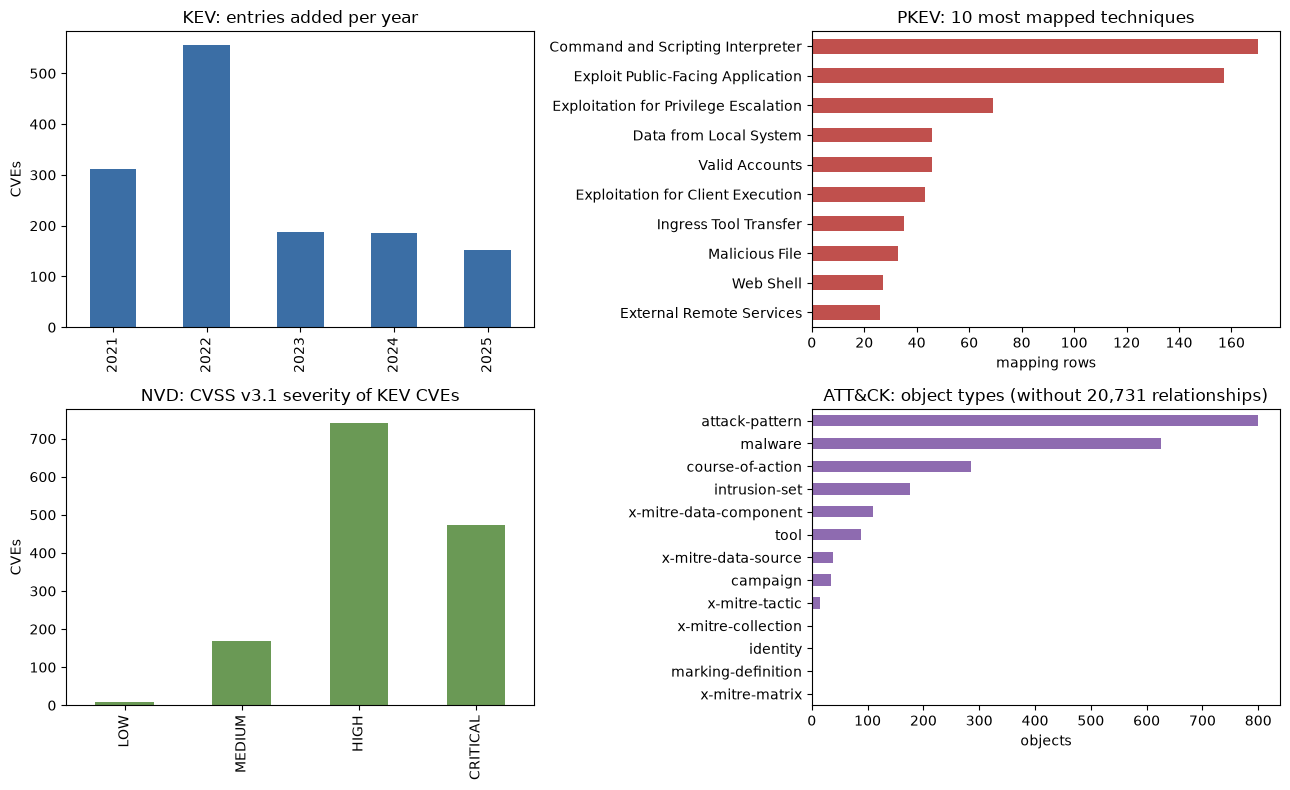

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
kev.groupby(kev.dateAdded.dt.year).size().plot.bar(ax=ax[0,0], color="#3b6ea5"); ax[0,0].set(title="KEV: entries added per year", xlabel="", ylabel="CVEs")
top = pkev.groupby("attack_object_name").size().sort_values().tail(10); top.plot.barh(ax=ax[0,1], color="#c0504d")
ax[0,1].set(title="PKEV: 10 most mapped techniques", ylabel="", xlabel="mapping rows")
nvd.severity.value_counts().reindex(["LOW","MEDIUM","HIGH","CRITICAL"]).plot.bar(ax=ax[1,0], color="#6a9955"); ax[1,0].set(title="NVD: CVSS v3.1 severity of KEV CVEs", xlabel="", ylabel="CVEs")
types.drop("relationship").sort_values().plot.barh(ax=ax[1,1], color="#8e6bb0"); ax[1,1].set(title="ATT&CK: object types (without 20,731 relationships)", ylabel="", xlabel="objects")
plt.tight_layout(); plt.show()

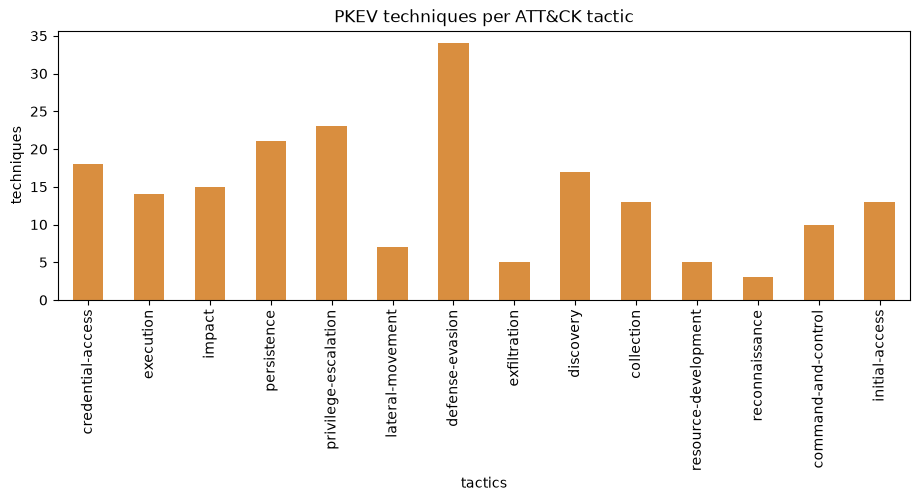

In [13]:
# Which tactics do the expert-mapped techniques fall under? (a technique can belong to several tactics)
tac = tech[tech.technique_id.isin(t_pkev)].explode("tactics").tactics.value_counts()
order = tactics.shortname.tolist()
tac.reindex(order).fillna(0).astype(int).plot.bar(figsize=(11, 3.5), color="#d98e3f", title="PKEV techniques per ATT&CK tactic"); plt.ylabel("techniques"); plt.show()

### Reading guide
Before Phase 2, be sure you can answer: *what is one row* in each source? *which column is the key* (KEV `cveID`, NVD `id`, PKEV `capability_id` + `attack_object_id`, ATT&CK external id `T####`)?
*what is missing* (NVD without CVSS v3.1, PKEV `comments`)? These answers drive the cleaning rules and the Django model.